<a href="https://colab.research.google.com/github/p1aster-ass/PreBolt/blob/main/lightningModel_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Connect Colab to my Google Drive so the code can read my files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Import the pandas library for working with tables
import pandas as pd

# Path
PROCESSED_DIR = '/content/drive/MyDrive/PreBolt/Data/Processed'

# Load the dataset into a table and treat the 'time' column as dates
df = pd.read_csv(PROCESSED_DIR + '/ml_dataset.csv', parse_dates=['time'])
print(df.shape)
df.head()

(468672, 32)


,time,cell_id,cell_lat,cell_lon,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,pressure_msl,precipitation,...,dewpoint_change_3h,MONTH,HOUR,lightning_now,strikes_now,max_kA_now,positive_now,lightning_next_3h,strikes_next_3h,max_kA_next_3h
0,2017-11-09,0,29.75,34.25,14.9,90,13.3,955.4,1018.8,0.0,...,-0.5,11,0,0,0,0.0,0,0,0.0,0.0
1,2017-11-09,1,29.75,34.75,13.9,96,13.4,937.5,1018.8,0.0,...,-0.2,11,0,0,0,0.0,0,0,0.0,0.0
2,2017-11-09,2,29.75,35.25,13.2,96,12.6,912.7,1018.6,0.1,...,0.0,11,0,0,0,0.0,0,0,0.0,0.0
3,2017-11-09,3,29.75,35.75,11.2,91,9.8,902.9,1017.5,0.0,...,-0.1,11,0,0,0,0.0,0,0,0.0,0.0
4,2017-11-09,100,30.25,34.25,16.5,79,12.7,980.5,1018.4,0.0,...,-1.3,11,0,0,0,0.0,0,0,0.0,0.0


In [3]:
# Load the table that describes the role of each column
column_roles = pd.read_csv(PROCESSED_DIR + '/data_dictionary.csv')

# Mark which rows have a role that starts with "FEATURE"
is_feature = column_roles['role'].str.startswith("FEATURE")

# Take the column names of the rows marked as features
feature_cols = column_roles.loc[is_feature, 'column']
print(len(feature_cols))
print(feature_cols.to_list())

21
['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'pressure_msl', 'precipitation', 'rain', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'boundary_layer_height', 'total_column_integrated_water_vapour', 'pressure_change_3h', 'temp_change_3h', 'dewpoint_change_3h', 'MONTH', 'HOUR']


In [5]:
X = df[feature_cols]
y = df['lightning_next_3h']

print(X.shape)
print(y.shape)
print(y.value_counts())

(468672, 21)
(468672,)
lightning_next_3h
0    454971
1     13701
Name: count, dtype: int64


In [6]:
# Mark which rows belong to the test season
is_test = df['time'] >= '2019-10-01'

# Training data: all rows before the test season (~ = !)
X_train = X[~is_test]
y_train = y[~is_test]

# Test data: rows in the test season
X_test = X[is_test]
y_test = y[is_test]

# Print number of rows and number of lightning rows in each part
print('Train: ', 'x: ', len(X_train),'y: ' ,y_train.sum())
print('Test: ', ' x: ', len(X_test),'y: ' , y_test.sum())

Train:  x:  362112 y:  9109
Test:   x:  106560 y:  4592


In [32]:
# Import the decision tree model from scikit-learn
from sklearn.tree import DecisionTreeClassifier

# Create a decision tree with up to N levels of questions, giving extra weight to lightning rows
tree = DecisionTreeClassifier(max_depth=3, class_weight= 'balanced')

# Train the tree on the training data
tree.fit(X_train, y_train)

# Print a message when training is done
print('Training done')

Training done


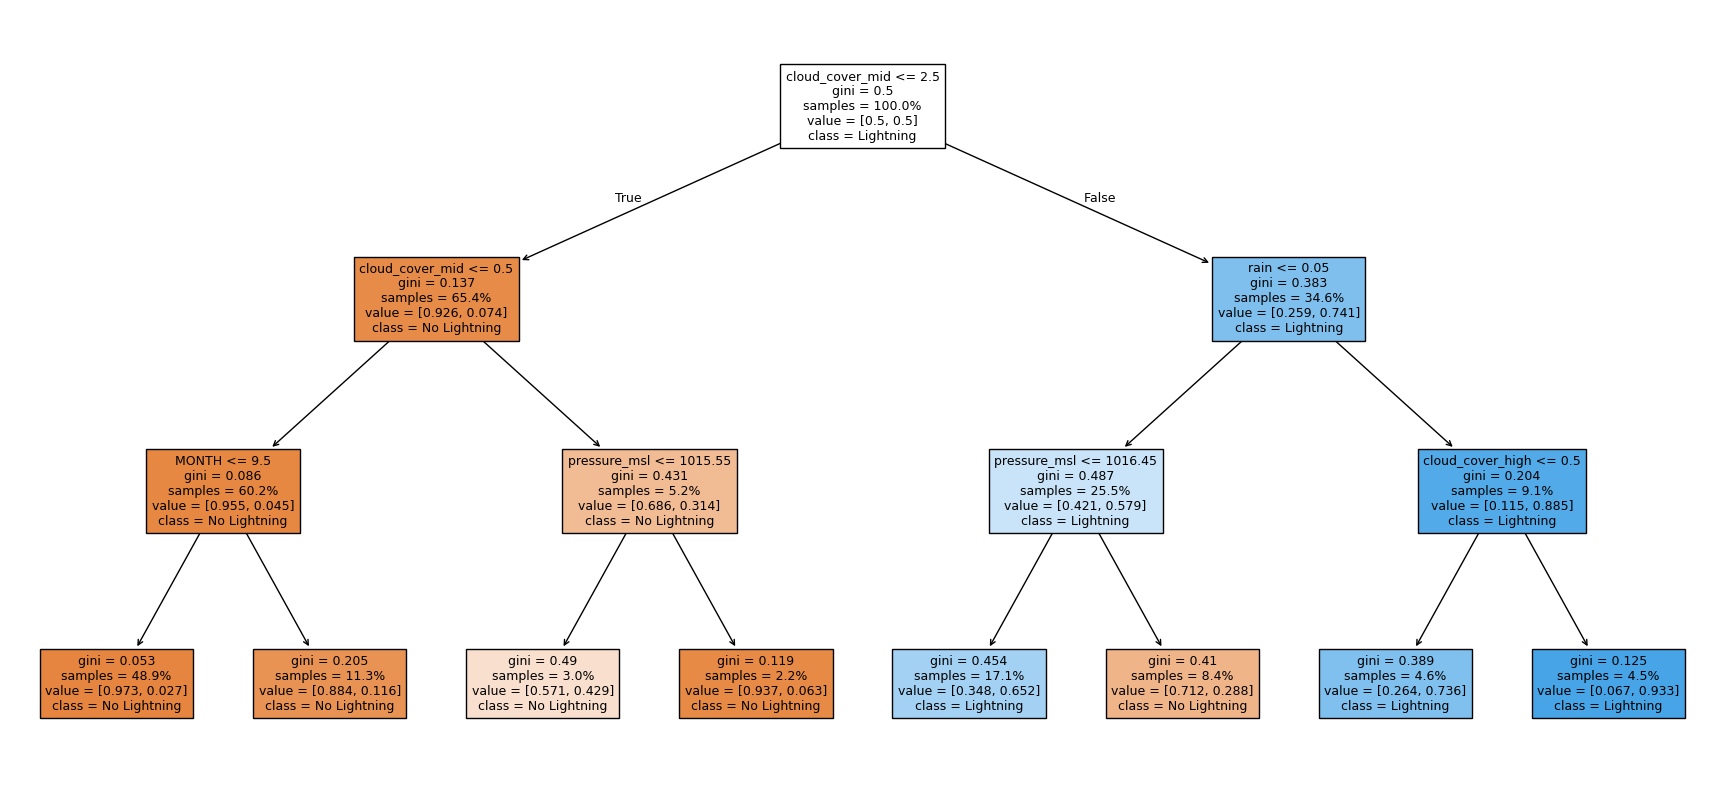

In [11]:
# Import the plotting library and the tree-drawing function
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Open a large drawing area
plt.figure(figsize=(22,10))

# Draw the tree with feature names, class names and colors
plot_tree(tree, feature_names=feature_cols.to_list(), class_names=['No Lightning', 'Lightning'], filled=True, proportion = True, fontsize = 9)

# Show the drawing
plt.show() # this is the tree for a max depth=3

In [36]:
# Import the functions that measure the model
from sklearn.metrics import confusion_matrix, recall_score, precision_score

# Let the forest predict an answer for every test row
y_pred = forest.predict(X_test)

# Split the confusion matrix into its 4 counts
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Calculate recall and precision
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

# Print one summary row
print('max_depth | caught | missed | false alarms | recall | precision')
print(f'forest | {tp:,} | {fn:,} | {fp:,} | {recall:.3f} | {precision:.3f}')

max_depth | caught | missed | false alarms | recall | precision
forest | 2,750 | 1,842 | 6,132 | 0.599 | 0.310


In [38]:
# Import the functions that measure the model
from sklearn.metrics import confusion_matrix, recall_score, precision_score

# Let the forest predict an answer for every train row
y_pred_train = forest.predict(X_train)

# Split the confusion matrix into its 4 counts
tn, fp, fn, tp = confusion_matrix(y_train, y_pred_train).ravel()

# Calculate recall and precision
recall = recall_score(y_train, y_pred_train)
precision = precision_score(y_train, y_pred_train)

# Print one summary row
print('max_depth | caught | missed | false alarms | recall | precision')
print(f'forest | {tp:,} | {fn:,} | {fp:,} | {recall:.3f} | {precision:.3f}')

max_depth | caught | missed | false alarms | recall | precision
forest | 8,864 | 245 | 24,199 | 0.973 | 0.268


In [22]:
# Get the chance of lightning (0 to 1) for every test row
tree.predict_proba(X_test)[:,1]

# Print the first 10 chances next to the real answers
print(tree.predict_proba(X_test)[:,1][:10])
print(y_test[:10].to_list())

[0.11580411 0.11580411 0.11580411 0.11580411 0.11580411 0.11580411
 0.11580411 0.11580411 0.11580411 0.11580411]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [35]:
# Import the random forest model
from sklearn.ensemble import RandomForestClassifier

# Create a forest of 100 trees (parameters from the table)
forest = RandomForestClassifier(n_estimators=100, min_samples_leaf= 50, class_weight= 'balanced_subsample', n_jobs= -1,random_state= 42)

# Train the forest on the training data
forest.fit(X_train,y_train)

# Print a message when training is done
print('Training done')

Training done


In [39]:
# Import the PR-AUC function
from sklearn.metrics import average_precision_score

# Chance of lightning for every test row, from the tree and from the forest
prob_tree = tree.predict_proba(X_test)[:,1]
prob_forest = forest.predict_proba(X_test)[:,1]
average = average_precision_score(y_test, prob_forest)

# Print the PR-AUC of each model, and the score of random guessing
print(f'tree: {average_precision_score(y_test, prob_tree):.3f}')
print(f'forest: {average_precision_score(y_test, prob_forest):.3f}')
print(f'random: {average_precision_score(y_test, [0]*len(y_test)):.3f}')

tree: 0.240
forest: 0.421
random: 0.043


In [40]:
# Print the header of the table
print('threshold | caught | missed | false alarms | recall | precision')

# Try several thresholds
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:

    # Turn chances into alerts (1/0) using this threshold
    alerts = (prob_forest >= t).astype(int)

    # Split the confusion matrix into its 4 counts
    tn, fp, fn, tp = confusion_matrix(y_test, alerts).ravel()

    # Calculate recall and precision
    recall = recall_score(y_test, alerts)
    precision = precision_score(y_test, alerts)

    # Print one row: threshold, caught, missed, false alarms, recall, precision
    print(f'{t} | {tp:,} | {fn:,} | {fp:,} | {recall:.3f} | {precision:.3f}')

threshold | caught | missed | false alarms | recall | precision
0.2 | 4,133 | 459 | 23,140 | 0.900 | 0.152
0.3 | 3,649 | 943 | 14,448 | 0.795 | 0.202
0.4 | 3,150 | 1,442 | 9,218 | 0.686 | 0.255
0.5 | 2,750 | 1,842 | 6,132 | 0.599 | 0.310
0.6 | 2,400 | 2,192 | 4,105 | 0.523 | 0.369
0.7 | 2,006 | 2,586 | 2,636 | 0.437 | 0.432
0.8 | 1,585 | 3,007 | 1,459 | 0.345 | 0.521


In [42]:
# Import the library that saves Python objects to files
import joblib

# Pack the model together with what the server needs to use it
bundle = {
    'model': forest,
    'feature_cols': feature_cols.to_list(),
    'thresholds': {'sensitive': 0.3, 'normal': 0.7},
}

# Save the package to the Models folder in Drive
joblib.dump(bundle, '/content/drive/MyDrive/PreBolt/Models/my_forest.joblib')

# Print a message when saving is done
print('saving is done')

saving is done


In [43]:
# Load the saved package from Drive
loaded = joblib.load('/content/drive/MyDrive/PreBolt/Models/my_forest.joblib')

# Find the test row where the forest gave the highest chance of lightning
i = prob_forest.argmax()

# Take that single row, with the columns in the order saved in the package
row = X_test.iloc[[i]][loaded['feature_cols']]

# Get the chance of lightning for that row from the loaded model
chance = loaded['model'].predict_proba(row)[0, 1]

# Print the chance, both alerts (sensitive / normal), and the real answer
print(f"Highest chance of lightning found: {chance:.3f}")
print(f"Sensitive alert (>= {loaded['thresholds']['sensitive']}): {chance >= loaded['thresholds']['sensitive']}")
print(f"Normal alert (>= {loaded['thresholds']['normal']}): {chance >= loaded['thresholds']['normal']}")
print(f"Real answer: {y_test.iloc[i]}")

Highest chance of lightning found: 0.986
Sensitive alert (>= 0.3): True
Normal alert (>= 0.7): True
Real answer: 1
